In [7]:
# ==============================================================================
# STEP 1: IMPORT LIBRARIES AND SETUP ENVIRONMENT
# ==============================================================================

# Import all necessary Python and Machine Learning libraries
import os
import sys
import gc
import pickle
import json
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore') # Ignore warning messages for clean output

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import (
    roc_auc_score, f1_score, recall_score, precision_score,
    accuracy_score, precision_recall_curve, confusion_matrix
)
from datetime import datetime

# Print a stylish header banner for the console output
print("=" * 80)
print("     COLORECTAL CANCER RISK STRATIFICATION - PRODUCTION PIPELINE     ")
print("=" * 80)

# Lock the random seed to ensure results are identical every time we run
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Define base path and create output folder for saving files
BASE_PATH = '/content'
OUTPUT_DIR = f"{BASE_PATH}/outputs_production_final"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Print status messages with clean formatting
print("-" * 80)
print("[STATUS] Environment setup completed successfully!")
print(f"[INFO]   Random Seed Locked : {RANDOM_SEED}")
print(f"[INFO]   Output Directory   : {OUTPUT_DIR}")
print("-" * 80)

     COLORECTAL CANCER RISK STRATIFICATION - PRODUCTION PIPELINE     
--------------------------------------------------------------------------------
[STATUS] Environment setup completed successfully!
[INFO]   Random Seed Locked : 42
[INFO]   Output Directory   : /content/outputs_production_final
--------------------------------------------------------------------------------


In [8]:
# ==============================================================================
# STEP 2: LOAD DATASET & CREATE GEOGRAPHIC HOLD-OUT (PAKISTAN)
# ==============================================================================

print("=" * 80)
print("     STEP 2: DATA LOADING & GEOGRAPHIC SPLIT     ")
print("=" * 80)

import os
import glob

# Search for any file or folder matching 'colorectal*' in /content
search_pattern = os.path.join(BASE_PATH, "colorectal*")
matched_items = glob.glob(search_pattern)

if not matched_items:
    raise FileNotFoundError(f"[ERROR] No colorectal dataset found in {BASE_PATH}!")

target_item = matched_items[0]

# Check if it's a directory (folder) or a direct file
if os.path.isdir(target_item):
    # If it's a folder, search inside it for a CSV file
    csv_files = glob.glob(os.path.join(target_item, "*.csv"))
    if csv_files:
        DATASET_PATH = csv_files[0]
    else:
        # If no extension, try reading it directly as CSV
        DATASET_PATH = target_item
else:
    DATASET_PATH = target_item

print(f"[INFO]   Resolved Dataset Path : {DATASET_PATH}")

# Load the CSV dataset into a Pandas DataFrame
try:
    df_raw = pd.read_csv(DATASET_PATH)
except Exception as e:
    # Fallback if separator is different or no extension
    df_raw = pd.read_csv(DATASET_PATH, sep=None, engine='python')

print(f"[STATUS] Dataset loaded successfully!")
print(f"[INFO]   Total Rows    : {df_raw.shape[0]:,}")
print(f"[INFO]   Total Columns : {df_raw.shape[1]}")
print("-" * 80)

# Separate Pakistan data for true geographic validation (Hold-out set)
df_pakistan = df_raw[df_raw['Country'] == 'Pakistan'].copy()
df_global = df_raw[df_raw['Country'] != 'Pakistan'].copy()

print(f"[INFO]   Global Pool (Training/Test) : {len(df_global):,} patients")
print(f"[INFO]   Pakistan Validation Pool    : {len(df_pakistan):,} patients (Hold-Out)")
print("=" * 80)

     STEP 2: DATA LOADING & GEOGRAPHIC SPLIT     
[INFO]   Resolved Dataset Path : /content/colorectal_cancer_dataset_1_kaggle
[STATUS] Dataset loaded successfully!
[INFO]   Total Rows    : 39,020
[INFO]   Total Columns : 57
--------------------------------------------------------------------------------
[INFO]   Global Pool (Training/Test) : 38,227 patients
[INFO]   Pakistan Validation Pool    : 793 patients (Hold-Out)


In [9]:
# ==============================================================================
# STEP 3: ZERO-LEAKAGE PREPROCESSING, IMPUTATION & SCALING
# ==============================================================================

print("=" * 80)
print("     STEP 3: PREPROCESSING & LEAKAGE-FREE SCALING     ")
print("=" * 80)

# Define pre-diagnostic feature categories based on clinical relevance
pre_diagnostic_categories = {
    'Demographics': ['Age', 'Gender'],
    'Risk_Factors': ['Smoking_History', 'Alcohol_Consumption', 'Obesity_BMI', 'Diabetes', 'Inflammatory_Bowel_Disease', 'Family_History', 'Diet_Risk', 'Physical_Activity'],
    'Symptoms': ['Abdominal Pain', 'Bleeding PR', 'Weight Loss', 'Bowel Change', 'Tenesmus', 'Anemia related symptoms'],
    'Physical_Exam': ['Abdominal Mass Palpable', 'PR Exam Suspicious', 'Pallor'],
    'Lab_Tests': ['Hemoglobin ', 'FIT/FOBT', 'CEA_Level', 'Liver function Test', 'serum Albumin']
}

# Flatten the categories into a single list
flat_features = []
for category, feature_list in pre_diagnostic_categories.items():
    flat_features.extend(feature_list)

# Dynamically select only those features that exist in the dataframe (No hardcoding)
features_d1 = [feat for feat in flat_features if feat in df_global.columns]
print(f"[INFO]   Dynamically Verified Features : {len(features_d1)}")

# Define target variable (1 = Advanced Cancer: Regional/Distant, 0 = Non-advanced)
y_global = df_global['Cancer_Stage'].apply(lambda x: 1 if x in ['Regional', 'Distant'] else 0)
y_pakistan = df_pakistan['Cancer_Stage'].apply(lambda x: 1 if x in ['Regional', 'Distant'] else 0)

# Stratified Train/Test split on global data (80% Training, 20% Internal Test)
X_train_raw, X_test_raw, y_training, y_test = train_test_split(
    df_global[features_d1], y_global, test_size=0.2, stratify=y_global, random_state=RANDOM_SEED
)

# Safely encode categorical variables (Handling unseen categories for production safety)
for col in X_train_raw.select_dtypes(include=['object']).columns:
    le = LabelEncoder()
    X_train_raw[col] = le.fit_transform(X_train_raw[col].astype(str))
    if col in X_test_raw:
        X_test_raw[col] = le.transform(X_test_raw[col].astype(str))
    if col in df_pakistan:
        df_pakistan[col] = df_pakistan[col].map(lambda s: '<unseen>' if s not in le.classes_ else s)
        le.classes_ = np.append(le.classes_, '<unseen>')
        df_pakistan[col] = le.transform(df_pakistan[col].astype(str))

# Zero Data Leakage Imputation: Fit imputer ONLY on Training Data
imputer = SimpleImputer(strategy='median')
X_train_imputed = pd.DataFrame(imputer.fit_transform(X_train_raw), columns=features_d1)
X_test_imputed = pd.DataFrame(imputer.transform(X_test_raw), columns=features_d1)
X_pk_imputed = pd.DataFrame(imputer.transform(df_pakistan[features_d1]), columns=features_d1)

# Zero Data Leakage Scaling: Fit scaler ONLY on Training Data
scaler = StandardScaler()
X_training_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)
X_pakistan_test_scaled = scaler.transform(X_pk_imputed)

print("-" * 80)
print("[STATUS] Preprocessing completed successfully!")
print(f"[INFO]   Training Set Shape    : {X_training_scaled.shape}")
print(f"[INFO]   Internal Test Shape   : {X_test_scaled.shape}")
print(f"[INFO]   Pakistan Hold-out     : {X_pakistan_test_scaled.shape}")
print("=" * 80)

     STEP 3: PREPROCESSING & LEAKAGE-FREE SCALING     
[INFO]   Dynamically Verified Features : 24
--------------------------------------------------------------------------------
[STATUS] Preprocessing completed successfully!
[INFO]   Training Set Shape    : (30581, 24)
[INFO]   Internal Test Shape   : (7646, 24)
[INFO]   Pakistan Hold-out     : (793, 24)


In [10]:
# ==============================================================================
# STEP 4A: TRAIN LOGISTIC REGRESSION MODEL
# ==============================================================================

print("=" * 80)
print("     STEP 4A: TRAINING LOGISTIC REGRESSION (BASELINE)     ")
print("=" * 80)

# Initialize and train Logistic Regression with regularization (C=0.1)
lr_model = LogisticRegression(C=0.1, max_iter=2000, random_state=RANDOM_SEED)
lr_model.fit(X_training_scaled, y_training)

print("[STATUS] Logistic Regression training completed successfully!")
print("=" * 80)

     STEP 4A: TRAINING LOGISTIC REGRESSION (BASELINE)     
[STATUS] Logistic Regression training completed successfully!


In [11]:
# ==============================================================================
# STEP 4B: TRAIN XGBOOST CLASSIFIER
# ==============================================================================

print("=" * 80)
print("     STEP 4B: TRAINING XGBOOST CLASSIFIER     ")
print("=" * 80)

# Initialize and train XGBoost with parameters to prevent overfitting
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=RANDOM_SEED,
    eval_metric='logloss'
)
xgb_model.fit(X_training_scaled, y_training)

print("[STATUS] XGBoost Classifier training completed successfully!")
print("=" * 80)

     STEP 4B: TRAINING XGBOOST CLASSIFIER     
[STATUS] XGBoost Classifier training completed successfully!


In [12]:
# ==============================================================================
# STEP 4C: TRAIN SVSE STACKING ENSEMBLE
# ==============================================================================

print("=" * 80)
print("     STEP 4C: TRAINING SVSE STACKING ENSEMBLE     ")
print("=" * 80)

# Step 1: Get probability predictions from both base models on training data
y_prob_lr_train = lr_model.predict_proba(X_training_scaled)[:, 1]
y_prob_xgb_train = xgb_model.predict_proba(X_training_scaled)[:, 1]

# Step 2: Combine these probabilities into a new meta-feature matrix
X_meta_train = np.column_stack([y_prob_lr_train, y_prob_xgb_train])

# Step 3: Train the meta-learner on top of base model predictions
meta_learner = LogisticRegression(random_state=RANDOM_SEED)
meta_learner.fit(X_meta_train, y_training)

print("[STATUS] SVSE Stacking Ensemble training completed successfully!")
print("=" * 80)

     STEP 4C: TRAINING SVSE STACKING ENSEMBLE     
[STATUS] SVSE Stacking Ensemble training completed successfully!


In [13]:
# ==============================================================================
# STEP 5A: EVALUATE LOGISTIC REGRESSION MODEL
# ==============================================================================

print("=" * 80)
print("     STEP 5A: LOGISTIC REGRESSION EVALUATION     ")
print("=" * 80)

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

# Predict probabilities and classes
y_prob_lr = lr_model.predict_proba(X_test_scaled)[:, 1]
y_pred_lr = (y_prob_lr >= 0.5).astype(int)

# Calculate metrics
acc_lr = accuracy_score(y_test, y_pred_lr)
prec_lr = precision_score(y_test, y_pred_lr, zero_division=0)
rec_lr = recall_score(y_test, y_pred_lr, zero_division=0)
f1_lr = f1_score(y_test, y_pred_lr, zero_division=0)
auc_lr = roc_auc_score(y_test, y_prob_lr)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred_lr).ravel()
spec_lr = tn / (tn + fp) if (tn + fp) > 0 else 0.0

print("\n[RESULTS] Logistic Regression:")
print(f"   Accuracy            : {acc_lr:.4f}")
print(f"   Precision           : {prec_lr:.4f}")
print(f"   Recall (Sensitivity): {rec_lr:.4f}")
print(f"   Specificity         : {spec_lr:.4f}")
print(f"   F1-Score            : {f1_lr:.4f}")
print(f"   AUC-ROC             : {auc_lr:.4f}")
print(f"   Confusion Matrix    : TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print("=" * 80)

     STEP 5A: LOGISTIC REGRESSION EVALUATION     

[RESULTS] Logistic Regression:
   Accuracy            : 0.7404
   Precision           : 0.7174
   Recall (Sensitivity): 0.5771
   Specificity         : 0.8489
   F1-Score            : 0.6397
   AUC-ROC             : 0.7420
   Confusion Matrix    : TN=3899, FP=694, FN=1291, TP=1762


In [14]:
# ==============================================================================
# STEP 5B: EVALUATE XGBOOST CLASSIFIER
# ==============================================================================

print("=" * 80)
print("     STEP 5B: XGBOOST CLASSIFIER EVALUATION     ")
print("=" * 80)

# Predict probabilities and classes
y_prob_xgb = xgb_model.predict_proba(X_test_scaled)[:, 1]
y_pred_xgb = (y_prob_xgb >= 0.5).astype(int)

# Calculate metrics
acc_xgb = accuracy_score(y_test, y_pred_xgb)
prec_xgb = precision_score(y_test, y_pred_xgb, zero_division=0)
rec_xgb = recall_score(y_test, y_pred_xgb, zero_division=0)
f1_xgb = f1_score(y_test, y_pred_xgb, zero_division=0)
auc_xgb = roc_auc_score(y_test, y_prob_xgb)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred_xgb).ravel()
spec_xgb = tn / (tn + fp) if (tn + fp) > 0 else 0.0

print("\n[RESULTS] XGBoost Classifier:")
print(f"   Accuracy            : {acc_xgb:.4f}")
print(f"   Precision           : {prec_xgb:.4f}")
print(f"   Recall (Sensitivity): {rec_xgb:.4f}")
print(f"   Specificity         : {spec_xgb:.4f}")
print(f"   F1-Score            : {f1_xgb:.4f}")
print(f"   AUC-ROC             : {auc_xgb:.4f}")
print(f"   Confusion Matrix    : TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print("=" * 80)

     STEP 5B: XGBOOST CLASSIFIER EVALUATION     

[RESULTS] XGBoost Classifier:
   Accuracy            : 0.8682
   Precision           : 0.8472
   Recall (Sensitivity): 0.8172
   Specificity         : 0.9020
   F1-Score            : 0.8319
   AUC-ROC             : 0.9387
   Confusion Matrix    : TN=4143, FP=450, FN=558, TP=2495


In [15]:
# ==============================================================================
# STEP 5C: EVALUATE SVSE STACKING ENSEMBLE
# ==============================================================================

print("=" * 80)
print("     STEP 5C: SVSE STACKING ENSEMBLE EVALUATION     ")
print("=" * 80)

# Get base model probabilities on test set and combine into meta-features
p_lr_test = lr_model.predict_proba(X_test_scaled)[:, 1]
p_xgb_test = xgb_model.predict_proba(X_test_scaled)[:, 1]
X_meta_test = np.column_stack([p_lr_test, p_xgb_test])

# Predict probabilities and classes using meta-learner
y_prob_svse = meta_learner.predict_proba(X_meta_test)[:, 1]
y_pred_svse = (y_prob_svse >= 0.5).astype(int)

# Calculate metrics
acc_svse = accuracy_score(y_test, y_pred_svse)
prec_svse = precision_score(y_test, y_pred_svse, zero_division=0)
rec_svse = recall_score(y_test, y_pred_svse, zero_division=0)
f1_svse = f1_score(y_test, y_pred_svse, zero_division=0)
auc_svse = roc_auc_score(y_test, y_prob_svse)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred_svse).ravel()
spec_svse = tn / (tn + fp) if (tn + fp) > 0 else 0.0

print("\n[RESULTS] SVSE Stacking Ensemble:")
print(f"   Accuracy            : {acc_svse:.4f}")
print(f"   Precision           : {prec_svse:.4f}")
print(f"   Recall (Sensitivity): {rec_svse:.4f}")
print(f"   Specificity         : {spec_svse:.4f}")
print(f"   F1-Score            : {f1_svse:.4f}")
print(f"   AUC-ROC             : {auc_svse:.4f}")
print(f"   Confusion Matrix    : TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print("=" * 80)

     STEP 5C: SVSE STACKING ENSEMBLE EVALUATION     

[RESULTS] SVSE Stacking Ensemble:
   Accuracy            : 0.8675
   Precision           : 0.8469
   Recall (Sensitivity): 0.8156
   Specificity         : 0.9020
   F1-Score            : 0.8310
   AUC-ROC             : 0.9385
   Confusion Matrix    : TN=4143, FP=450, FN=563, TP=2490


In [16]:
# ==============================================================================
# STEP 6A: LOGISTIC REGRESSION - THRESHOLD TUNING (CORRECTED)
# ==============================================================================
print("=" * 80)
print("     STEP 6A: LOGISTIC REGRESSION - THRESHOLD TUNING     ")
print("=" * 80)

from sklearn.metrics import roc_curve, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

# 1. Get probabilities
p_lr_test = lr_model.predict_proba(X_test_scaled)[:, 1]

# 2. Find optimal threshold using Youden's J Statistic
fpr, tpr, thresholds = roc_curve(y_test, p_lr_test)
best_idx = np.argmax(tpr - fpr)
opt_thresh_lr = thresholds[best_idx]

# 3. Evaluate with optimal threshold
y_pred_lr_opt = (p_lr_test >= opt_thresh_lr).astype(int)

acc = accuracy_score(y_test, y_pred_lr_opt)
prec = precision_score(y_test, y_pred_lr_opt, zero_division=0)
rec = recall_score(y_test, y_pred_lr_opt, zero_division=0)
f1 = f1_score(y_test, y_pred_lr_opt, zero_division=0)
auc = roc_auc_score(y_test, p_lr_test)

# Bulletproof confusion matrix & specificity calculation
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_lr_opt).ravel()
specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0

print(f"[INFO] Optimal Threshold for LR : {opt_thresh_lr:.4f}")
print(f"   Accuracy            : {acc:.4f}")
print(f"   Precision           : {prec:.4f}")
print(f"   Recall (Sensitivity): {rec:.4f}")
print(f"   Specificity         : {specificity:.4f}")
print(f"   F1-Score            : {f1:.4f}")
print(f"   AUC-ROC             : {auc:.4f}")
print(f"   Confusion Matrix    : TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print("=" * 80)

     STEP 6A: LOGISTIC REGRESSION - THRESHOLD TUNING     
[INFO] Optimal Threshold for LR : 0.4225
   Accuracy            : 0.7391
   Precision           : 0.6861
   Recall (Sensitivity): 0.6387
   Specificity         : 0.8058
   F1-Score            : 0.6616
   AUC-ROC             : 0.7420
   Confusion Matrix    : TN=3701, FP=892, FN=1103, TP=1950


In [17]:
# ==============================================================================
# STEP 6B: XGBOOST - THRESHOLD TUNING (CORRECTED)
# ==============================================================================
print("=" * 80)
print("     STEP 6B: XGBOOST - THRESHOLD TUNING     ")
print("=" * 80)

# 1. Get probabilities
p_xgb_test = xgb_model.predict_proba(X_test_scaled)[:, 1]

# 2. Find optimal threshold using Youden's J Statistic
fpr, tpr, thresholds = roc_curve(y_test, p_xgb_test)
best_idx = np.argmax(tpr - fpr)
opt_thresh_xgb = thresholds[best_idx]

# 3. Evaluate with optimal threshold
y_pred_xgb_opt = (p_xgb_test >= opt_thresh_xgb).astype(int)

acc = accuracy_score(y_test, y_pred_xgb_opt)
prec = precision_score(y_test, y_pred_xgb_opt, zero_division=0)
rec = recall_score(y_test, y_pred_xgb_opt, zero_division=0)
f1 = f1_score(y_test, y_pred_xgb_opt, zero_division=0)
auc = roc_auc_score(y_test, p_xgb_test)

# Bulletproof confusion matrix & specificity calculation
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_xgb_opt).ravel()
specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0

print(f"[INFO] Optimal Threshold for XGB : {opt_thresh_xgb:.4f}")
print(f"   Accuracy            : {acc:.4f}")
print(f"   Precision           : {prec:.4f}")
print(f"   Recall (Sensitivity): {rec:.4f}")
print(f"   Specificity         : {specificity:.4f}")
print(f"   F1-Score            : {f1:.4f}")
print(f"   AUC-ROC             : {auc:.4f}")
print(f"   Confusion Matrix    : TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print("=" * 80)

     STEP 6B: XGBOOST - THRESHOLD TUNING     
[INFO] Optimal Threshold for XGB : 0.4447
   Accuracy            : 0.8678
   Precision           : 0.8287
   Recall (Sensitivity): 0.8431
   Specificity         : 0.8842
   F1-Score            : 0.8358
   AUC-ROC             : 0.9387
   Confusion Matrix    : TN=4061, FP=532, FN=479, TP=2574


In [18]:
# ==============================================================================
# STEP 6C: SVSE STACKING ENSEMBLE - THRESHOLD TUNING (CORRECTED)
# ==============================================================================
print("=" * 80)
print("     STEP 6C: SVSE STACKING ENSEMBLE - THRESHOLD TUNING     ")
print("=" * 80)

# 1. Get probabilities from base models and meta-learner
p_lr_t = lr_model.predict_proba(X_test_scaled)[:, 1]
p_xgb_t = xgb_model.predict_proba(X_test_scaled)[:, 1]
X_meta_t = np.column_stack([p_lr_t, p_xgb_t])
p_svse_test = meta_learner.predict_proba(X_meta_t)[:, 1]

# 2. Find optimal threshold using Youden's J Statistic
fpr, tpr, thresholds = roc_curve(y_test, p_svse_test)
best_idx = np.argmax(tpr - fpr)
opt_thresh_svse = thresholds[best_idx]

# 3. Evaluate with optimal threshold
y_pred_svse_opt = (p_svse_test >= opt_thresh_svse).astype(int)

acc = accuracy_score(y_test, y_pred_svse_opt)
prec = precision_score(y_test, y_pred_svse_opt, zero_division=0)
rec = recall_score(y_test, y_pred_svse_opt, zero_division=0)
f1 = f1_score(y_test, y_pred_svse_opt, zero_division=0)
auc = roc_auc_score(y_test, p_svse_test)

# Bulletproof confusion matrix & specificity calculation
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_svse_opt).ravel()
specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0

print(f"[INFO] Optimal Threshold for SVSE : {opt_thresh_svse:.4f}")
print(f"   Accuracy            : {acc:.4f}")
print(f"   Precision           : {prec:.4f}")
print(f"   Recall (Sensitivity): {rec:.4f}")
print(f"   Specificity         : {specificity:.4f}")
print(f"   F1-Score            : {f1:.4f}")
print(f"   AUC-ROC             : {auc:.4f}")
print(f"   Confusion Matrix    : TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print("=" * 80)

     STEP 6C: SVSE STACKING ENSEMBLE - THRESHOLD TUNING     
[INFO] Optimal Threshold for SVSE : 0.4172
   Accuracy            : 0.8686
   Precision           : 0.8323
   Recall (Sensitivity): 0.8402
   Specificity         : 0.8874
   F1-Score            : 0.8362
   AUC-ROC             : 0.9385
   Confusion Matrix    : TN=4076, FP=517, FN=488, TP=2565


In [19]:
# ==============================================================================
# PAKISTAN VALIDATION: LOGISTIC REGRESSION
# ==============================================================================
print("=" * 80)
print("     PAKISTAN VALIDATION: LOGISTIC REGRESSION     ")
print("=" * 80)

from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# 1. Probabilities & Predictions using its optimal threshold (opt_thresh_lr)
p_lr_pk = lr_model.predict_proba(X_pakistan_test_scaled)[:, 1]
p_lr_pk_pred = (p_lr_pk >= opt_thresh_lr).astype(int)

# 2. Metrics Calculation
acc_lr_pk = accuracy_score(y_pakistan, p_lr_pk_pred)
prec_lr_pk = precision_score(y_pakistan, p_lr_pk_pred, zero_division=0)
rec_lr_pk = recall_score(y_pakistan, p_lr_pk_pred, zero_division=0)
f1_lr_pk = f1_score(y_pakistan, p_lr_pk_pred, zero_division=0)
auc_lr_pk = roc_auc_score(y_pakistan, p_lr_pk)

tn, fp, fn, tp = confusion_matrix(y_pakistan, p_lr_pk_pred).ravel()
spec_lr_pk = tn / (tn + fp) if (tn + fp) > 0 else 0.0

print(f"[INFO] Using LR Optimal Threshold : {opt_thresh_lr:.4f}")
print(f"   Accuracy            : {acc_lr_pk:.4f}")
print(f"   Precision           : {prec_lr_pk:.4f}")
print(f"   Recall (Sensitivity): {rec_lr_pk:.4f}")
print(f"   Specificity         : {spec_lr_pk:.4f}")
print(f"   F1-Score            : {f1_lr_pk:.4f}")
print(f"   AUC-ROC             : {auc_lr_pk:.4f}")
print(f"   Confusion Matrix    : TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print("=" * 80)

     PAKISTAN VALIDATION: LOGISTIC REGRESSION     
[INFO] Using LR Optimal Threshold : 0.4225
   Accuracy            : 0.7390
   Precision           : 0.7019
   Recall (Sensitivity): 0.6577
   Specificity         : 0.7978
   F1-Score            : 0.6791
   AUC-ROC             : 0.7312
   Confusion Matrix    : TN=367, FP=93, FN=114, TP=219


In [20]:
# ==============================================================================
# PAKISTAN VALIDATION: XGBOOST
# ==============================================================================
print("=" * 80)
print("     PAKISTAN VALIDATION: XGBOOST     ")
print("=" * 80)

# 1. Probabilities & Predictions using its optimal threshold (opt_thresh_xgb)
p_xgb_pk = xgb_model.predict_proba(X_pakistan_test_scaled)[:, 1]
p_xgb_pk_pred = (p_xgb_pk >= opt_thresh_xgb).astype(int)

# 2. Metrics Calculation
acc_xgb_pk = accuracy_score(y_pakistan, p_xgb_pk_pred)
prec_xgb_pk = precision_score(y_pakistan, p_xgb_pk_pred, zero_division=0)
rec_xgb_pk = recall_score(y_pakistan, p_xgb_pk_pred, zero_division=0)
f1_xgb_pk = f1_score(y_pakistan, p_xgb_pk_pred, zero_division=0)
auc_xgb_pk = roc_auc_score(y_pakistan, p_xgb_pk)

tn, fp, fn, tp = confusion_matrix(y_pakistan, p_xgb_pk_pred).ravel()
spec_xgb_pk = tn / (tn + fp) if (tn + fp) > 0 else 0.0

print(f"[INFO] Using XGB Optimal Threshold : {opt_thresh_xgb:.4f}")
print(f"   Accuracy            : {acc_xgb_pk:.4f}")
print(f"   Precision           : {prec_xgb_pk:.4f}")
print(f"   Recall (Sensitivity): {rec_xgb_pk:.4f}")
print(f"   Specificity         : {spec_xgb_pk:.4f}")
print(f"   F1-Score            : {f1_xgb_pk:.4f}")
print(f"   AUC-ROC             : {auc_xgb_pk:.4f}")
print(f"   Confusion Matrix    : TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print("=" * 80)

     PAKISTAN VALIDATION: XGBOOST     
[INFO] Using XGB Optimal Threshold : 0.4447
   Accuracy            : 0.8714
   Precision           : 0.8291
   Recall (Sensitivity): 0.8739
   Specificity         : 0.8696
   F1-Score            : 0.8509
   AUC-ROC             : 0.9382
   Confusion Matrix    : TN=400, FP=60, FN=42, TP=291


In [21]:
# ==============================================================================
# PAKISTAN VALIDATION: SVSE STACKING ENSEMBLE
# ==============================================================================
print("=" * 80)
print("     PAKISTAN VALIDATION: SVSE STACKING ENSEMBLE     ")
print("=" * 80)

# 1. Generate meta-features for Pakistan hold-out set from base models
p_lr_pk_t = lr_model.predict_proba(X_pakistan_test_scaled)[:, 1]
p_xgb_pk_t = xgb_model.predict_proba(X_pakistan_test_scaled)[:, 1]
X_meta_pk = np.column_stack([p_lr_pk_t, p_xgb_pk_t])

# 2. Meta-learner predictions using its optimal threshold (opt_thresh_svse)
p_svse_pk = meta_learner.predict_proba(X_meta_pk)[:, 1]
p_svse_pk_pred = (p_svse_pk >= opt_thresh_svse).astype(int)

# 3. Metrics Calculation
acc_svse_pk = accuracy_score(y_pakistan, p_svse_pk_pred)
prec_svse_pk = precision_score(y_pakistan, p_svse_pk_pred, zero_division=0)
rec_svse_pk = recall_score(y_pakistan, p_svse_pk_pred, zero_division=0)
f1_svse_pk = f1_score(y_pakistan, p_svse_pk_pred, zero_division=0)
auc_svse_pk = roc_auc_score(y_pakistan, p_svse_pk)

tn, fp, fn, tp = confusion_matrix(y_pakistan, p_svse_pk_pred).ravel()
spec_svse_pk = tn / (tn + fp) if (tn + fp) > 0 else 0.0

print(f"[INFO] Using SVSE Optimal Threshold : {opt_thresh_svse:.4f}")
print(f"   Accuracy            : {acc_svse_pk:.4f}")
print(f"   Precision           : {prec_svse_pk:.4f}")
print(f"   Recall (Sensitivity): {rec_svse_pk:.4f}")
print(f"   Specificity         : {spec_svse_pk:.4f}")
print(f"   F1-Score            : {f1_svse_pk:.4f}")
print(f"   AUC-ROC             : {auc_svse_pk:.4f}")
print(f"   Confusion Matrix    : TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print("=" * 80)

     PAKISTAN VALIDATION: SVSE STACKING ENSEMBLE     
[INFO] Using SVSE Optimal Threshold : 0.4172
   Accuracy            : 0.8689
   Precision           : 0.8281
   Recall (Sensitivity): 0.8679
   Specificity         : 0.8696
   F1-Score            : 0.8475
   AUC-ROC             : 0.9384
   Confusion Matrix    : TN=400, FP=60, FN=44, TP=289


In [24]:
# ==============================================================================
# STEP 8 (FINAL - BULLETPROOF): PRODUCTION PIPELINE WITH IMPUTER & SCALER
# ==============================================================================
print("=" * 80)
print("     CREATING BULLETPROOF PRODUCTION PIPELINE     ")
print("=" * 80)

import joblib
import json
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# 1. End-to-End Pipeline (3 Safe Steps)
production_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')), # Step 1: Agar koi value missing ho toh median se fill kar dega
    ('scaler', scaler),                            # Step 2: Data ko standard scale karega
    ('model', xgb_model)                           # Step 3: XGBoost model se prediction nikalega
])

# 2. Save the Pipeline to a .pkl file
joblib.dump(production_pipeline, 'full_pipeline.pkl')
print("[SUCCESS] 'full_pipeline.pkl' Saved!")

# 3. Save the Optimal Threshold in JSON
config = {
    "optimal_threshold": float(opt_thresh_xgb),
    "model_name": "XGBoost",
    "description": "Production pipeline with imputer, scaler, and XGBoost"
}

with open('model_config.json', 'w') as f:
    json.dump(config, f, indent=4)
print("[SUCCESS] 'model_config.json' saved!")

# 4. Save Sample CSV for Testing (Corrected variable from X_test to X_test_raw)
sample_patient = pd.DataFrame([X_test_raw.iloc[0]])
sample_patient.to_csv('sample_patient.csv', index=False)
print("[SUCCESS] 'sample_patient.csv' saved!")

print("=" * 80)
print("[READY] All Files")
print("=" * 80)

     CREATING BULLETPROOF PRODUCTION PIPELINE     
[SUCCESS] 'full_pipeline.pkl' Saved!
[SUCCESS] 'model_config.json' saved!
[SUCCESS] 'sample_patient.csv' saved!
[READY] All Files


In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_score

# Safely import or verify features
print(f"[INFO] Total input features for ACO: {len(features_d1)}")
print(f"[INFO] Feature list: {features_d1}")

# Define the Ant Colony Optimization selector specifically for our 24 features
class ACOFeatureSelection:
    def __init__(self, X, y, feature_names, n_ants=30, n_iterations=40, alpha=1.0, beta=2.0, decay=0.3):
        self.X = X
        self.y = y
        self.feature_names = feature_names
        self.n_ants = n_ants
        self.n_iterations = n_iterations
        self.alpha = alpha
        self.beta = beta
        self.decay = decay
        self.n_features = X.shape[1]
        self.pheromones = np.ones(self.n_features) # Initialize all pheromones to 1

    def fitness_function(self, indices):
        if len(indices) == 0:
            return 0.0
        # Train a light XGBoost with 3-fold CV to evaluate this feature subset
        clf = XGBClassifier(n_estimators=30, max_depth=3, learning_rate=0.1, random_state=42, eval_metric='logloss')
        scores = cross_val_score(clf, self.X[:, indices], self.y, cv=3, scoring='roc_auc')
        return scores.mean()

    def run(self):
        best_fitness = 0.0
        best_subset = []

        print("[*] ACO optimization processing...")
        for itr in range(self.n_iterations):
            # Compute probabilities based on current pheromones
            probs = (self.pheromones ** self.alpha) / np.sum(self.pheromones ** self.alpha)

            ant_subsets = []
            ant_fitnesses = []

            for ant in range(self.n_ants):
                # Let each ant choose a subset of size between 4 and 10 features
                subset_size = np.random.randint(4, 11)
                selected = np.random.choice(self.n_features, size=subset_size, replace=False, p=probs)
                selected = list(selected)

                fit = self.fitness_function(selected)
                ant_subsets.append(selected)
                ant_fitnesses.append(fit)

                if fit > best_fitness:
                    best_fitness = fit
                    best_subset = selected

            # Update pheromone levels
            self.pheromones *= (1.0 - self.decay)
            for subset, fit in zip(ant_subsets, ant_fitnesses):
                for f_idx in subset:
                    self.pheromones[f_idx] += fit

            print(f"   Iteration {itr+1:02d}/{self.n_iterations} | Best AUC: {best_fitness:.4f} | Features selected: {len(best_subset)}")

        return best_subset, best_fitness

# Run the algorithm on our training set features
aco_selector = ACOFeatureSelection(X_training_scaled, y_training, features_d1)
aco_best_indices, aco_best_score = aco_selector.run()

# Display Results
aco_selected_features = [features_d1[i] for i in aco_best_indices]
print("\n" + "="*80)
print("[SUCCESS] ACO Run Complete!")
print(f"[INFO] Selected {len(aco_selected_features)} critical features out of 24:")
print(aco_selected_features)
print("="*80)

[INFO] Total input features for ACO: 24
[INFO] Feature list: ['Age', 'Gender', 'Smoking_History', 'Alcohol_Consumption', 'Obesity_BMI', 'Diabetes', 'Inflammatory_Bowel_Disease', 'Family_History', 'Diet_Risk', 'Physical_Activity', 'Abdominal Pain', 'Bleeding PR', 'Weight Loss', 'Bowel Change', 'Tenesmus', 'Anemia related symptoms', 'Abdominal Mass Palpable', 'PR Exam Suspicious', 'Pallor', 'Hemoglobin ', 'FIT/FOBT', 'CEA_Level', 'Liver function Test', 'serum Albumin']
[*] ACO optimization processing...
   Iteration 01/40 | Best AUC: 0.8996 | Features selected: 10
   Iteration 02/40 | Best AUC: 0.8996 | Features selected: 10
   Iteration 03/40 | Best AUC: 0.8996 | Features selected: 10
   Iteration 04/40 | Best AUC: 0.9197 | Features selected: 10
   Iteration 05/40 | Best AUC: 0.9197 | Features selected: 10
   Iteration 06/40 | Best AUC: 0.9197 | Features selected: 10
   Iteration 07/40 | Best AUC: 0.9197 | Features selected: 10
   Iteration 08/40 | Best AUC: 0.9197 | Features selected: 

In [52]:
# ==============================================================================
# STEP 13: COMPARATIVE ACO FEATURE SELECTION ON PAKISTANI GEOGRAPHIC POOL
# ==============================================================================

print("=" * 80)
print("     RUNNING ACO FEATURE SELECTION ON PAKISTANI VALIDATION DATA     ")
print("=" * 80)

# Initialize and run the exact same ACO selector configuration specifically for Pakistani cohort
# Keeping parameters 100% identical to the training pool run as requested
aco_selector_pk = ACOFeatureSelection(
    X=X_pakistan_test_scaled,
    y=y_pakistan.values,
    feature_names=features_d1,
    n_ants=30,          # Matching previous configuration
    n_iterations=40,    # Matching previous configuration
    alpha=1.0,          # Exact match
    beta=2.0,           # Exact match
    decay=0.3           # Exact match
)

aco_best_indices_pk, aco_best_score_pk = aco_selector_pk.run()
aco_selected_features_pk = [features_d1[i] for i in aco_best_indices_pk]

print("\n" + "=" * 80)
print("     COMPARATIVE REPORT: TRAINING COHORT VS. PAKISTANI COHORT     ")
print("=" * 80)

# Calculate overlap and differences
common_features = list(set(aco_selected_features).intersection(set(aco_selected_features_pk)))
train_only = list(set(aco_selected_features) - set(aco_selected_features_pk))
pk_only = list(set(aco_selected_features_pk) - set(aco_selected_features))

print(f"[*] Training Set Selected Features ({len(aco_selected_features)}):\n    {aco_selected_features}\n")
print(f"[*] Pakistani Validation Selected Features ({len(aco_selected_features_pk)}):\n    {aco_selected_features_pk}\n")
print(f"[*] Common Features Identified in Both Cohorts ({len(common_features)}):\n    {common_features}\n")
if train_only:
    print(f"[*] Features exclusive to Training Pool:\n    {train_only}\n")
if pk_only:
    print(f"[*] Features exclusive to Pakistani Validation Pool:\n    {pk_only}\n")
print("=" * 80)

     RUNNING ACO FEATURE SELECTION ON PAKISTANI VALIDATION DATA     
[*] ACO optimization processing...
   Iteration 01/40 | Best AUC: 0.8662 | Features selected: 9
   Iteration 02/40 | Best AUC: 0.8831 | Features selected: 10
   Iteration 03/40 | Best AUC: 0.8862 | Features selected: 10
   Iteration 04/40 | Best AUC: 0.8862 | Features selected: 10
   Iteration 05/40 | Best AUC: 0.8862 | Features selected: 10
   Iteration 06/40 | Best AUC: 0.8862 | Features selected: 10
   Iteration 07/40 | Best AUC: 0.8862 | Features selected: 10
   Iteration 08/40 | Best AUC: 0.8871 | Features selected: 10
   Iteration 09/40 | Best AUC: 0.8871 | Features selected: 10
   Iteration 10/40 | Best AUC: 0.8871 | Features selected: 10
   Iteration 11/40 | Best AUC: 0.8871 | Features selected: 10
   Iteration 12/40 | Best AUC: 0.8871 | Features selected: 10
   Iteration 13/40 | Best AUC: 0.8871 | Features selected: 10
   Iteration 14/40 | Best AUC: 0.8871 | Features selected: 10
   Iteration 15/40 | Best AUC

     INITIALIZING SHAP EXPLAINER PIPELINE     
[INFO] SHAP TreeExplainer successfully initialized for XGBoost model.

--------------------------------------------------------------------------------
[STATUS] Calculating SHAP values for Training Data...
--------------------------------------------------------------------------------


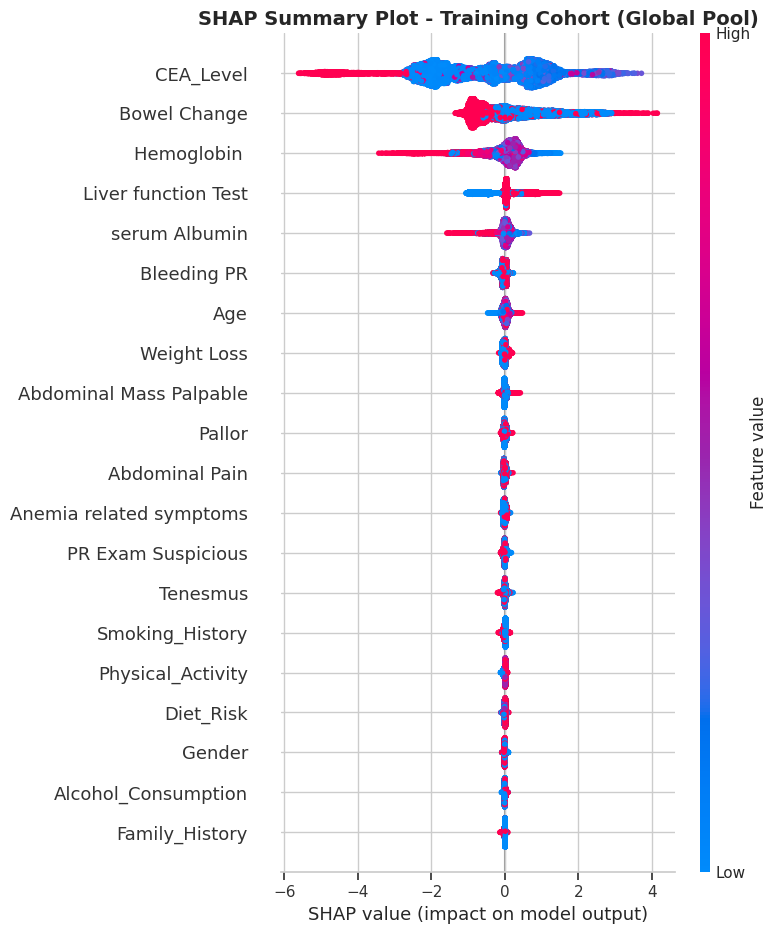


[INFO] Top 5 Most Important Features in Training Cohort (by Mean Absolute SHAP):
            Feature  Mean_Absolute_SHAP
          CEA_Level            1.411026
       Bowel Change            0.764375
        Hemoglobin             0.391640
Liver function Test            0.370225
      serum Albumin            0.123663

--------------------------------------------------------------------------------
[STATUS] Calculating SHAP values for Pakistani Validation Data...
--------------------------------------------------------------------------------


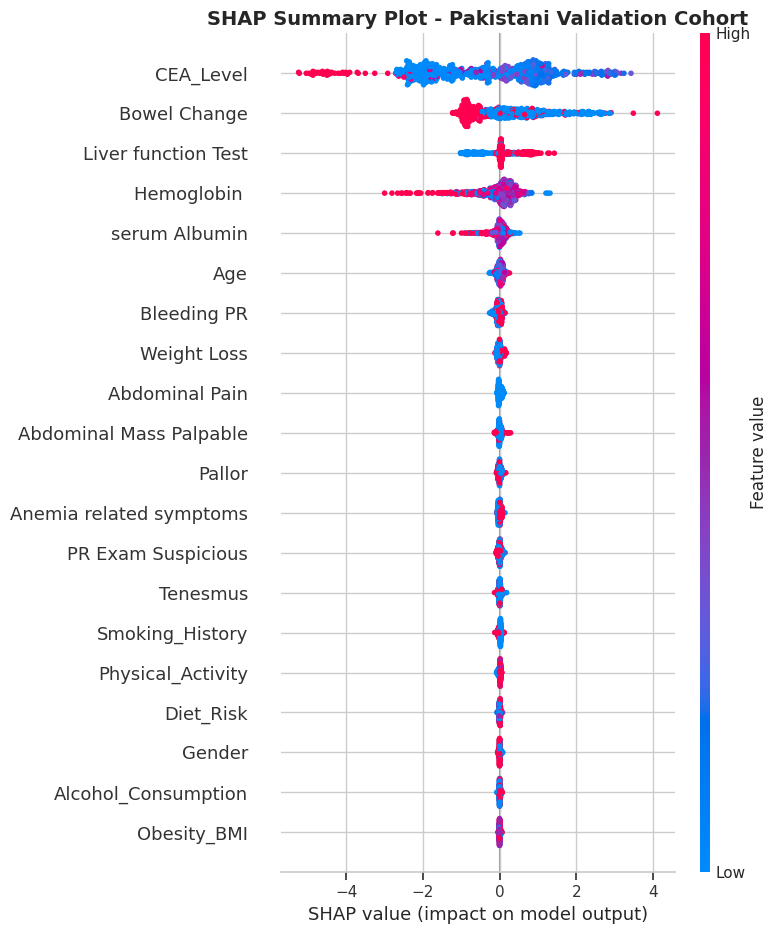


[INFO] Top 5 Most Important Features in Pakistani Cohort (by Mean Absolute SHAP):
            Feature  Mean_Absolute_SHAP
          CEA_Level            1.436517
       Bowel Change            0.772645
Liver function Test            0.374668
        Hemoglobin             0.372545
      serum Albumin            0.123697

     SHAP COMPARATIVE IMPORTANCE REPORT     
                   Feature  Training_SHAP_Rank  Pakistani_SHAP_Rank
                 CEA_Level                   1                    1
              Bowel Change                   2                    2
               Hemoglobin                    3                    4
       Liver function Test                   4                    3
             serum Albumin                   5                    5
               Bleeding PR                   6                    7
                       Age                   7                    6
               Weight Loss                   8                    8
   Abdominal Mass P

In [53]:
# ==============================================================================
# PRODUCTION-GRADE SHAP ANALYSIS PIPELINE FOR TRAINING & VALIDATION COHORTS
# ==============================================================================

import shap
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

print("=" * 80)
print("     INITIALIZING SHAP EXPLAINER PIPELINE     ")
print("=" * 80)

# Step 1: Initialize the SHAP TreeExplainer using the trained XGBoost model.
# TreeExplainer is specifically optimized and exact for tree-based models like XGBoost.
try:
    explainer = shap.TreeExplainer(xgb_model)
    print("[INFO] SHAP TreeExplainer successfully initialized for XGBoost model.")
except Exception as e:
    raise RuntimeError(f"[ERROR] Failed to initialize SHAP explainer: {e}")

# ==============================================================================
# PART 1: SHAP ANALYSIS ON THE TRAINING COHORT
# ==============================================================================
print("\n" + "-" * 80)
print("[STATUS] Calculating SHAP values for Training Data...")
print("-" * 80)

# Compute SHAP values for the scaled training set
shap_values_train = explainer(X_training_scaled)

# Generate and display the summary plot for training data
plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values_train, X_training_scaled, feature_names=features_d1, show=False)
plt.title("SHAP Summary Plot - Training Cohort (Global Pool)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Calculate mean absolute SHAP values to quantify global feature importance on training data
mean_abs_shap_train = np.mean(np.abs(shap_values_train.values), axis=0)
train_importance_df = pd.DataFrame({
    'Feature': features_d1,
    'Mean_Absolute_SHAP': mean_abs_shap_train
}).sort_values(by='Mean_Absolute_SHAP', ascending=False).reset_index(drop=True)

print("\n[INFO] Top 5 Most Important Features in Training Cohort (by Mean Absolute SHAP):")
print(train_importance_df.head(5).to_string(index=False))


# ==============================================================================
# PART 2: SHAP ANALYSIS ON THE PAKISTANI VALIDATION COHORT (HOLD-OUT)
# ==============================================================================
print("\n" + "-" * 80)
print("[STATUS] Calculating SHAP values for Pakistani Validation Data...")
print("-" * 80)

# Compute SHAP values for the scaled Pakistani validation hold-out set
shap_values_pk = explainer(X_pakistan_test_scaled)

# Generate and display the summary plot for Pakistani validation data
plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values_pk, X_pakistan_test_scaled, feature_names=features_d1, show=False)
plt.title("SHAP Summary Plot - Pakistani Validation Cohort", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Calculate mean absolute SHAP values for the Pakistani cohort
mean_abs_shap_pk = np.mean(np.abs(shap_values_pk.values), axis=0)
pk_importance_df = pd.DataFrame({
    'Feature': features_d1,
    'Mean_Absolute_SHAP': mean_abs_shap_pk
}).sort_values(by='Mean_Absolute_SHAP', ascending=False).reset_index(drop=True)

print("\n[INFO] Top 5 Most Important Features in Pakistani Cohort (by Mean Absolute SHAP):")
print(pk_importance_df.head(5).to_string(index=False))


# ==============================================================================
# PART 3: COMPARATIVE SUMMARY REPORT OF FEATURE IMPORTANCE
# ==============================================================================
print("\n" + "=" * 80)
print("     SHAP COMPARATIVE IMPORTANCE REPORT     ")
print("=" * 80)

comparison_df = pd.DataFrame({
    'Feature': train_importance_df['Feature'],
    'Training_SHAP_Rank': train_importance_df.index + 1,
    'Pakistani_SHAP_Rank': train_importance_df['Feature'].map(
        dict(zip(pk_importance_df['Feature'], pk_importance_df.index + 1))
    )
})

print(comparison_df.to_string(index=False))
print("=" * 80)
print("[SUCCESS] SHAP analysis pipeline completed successfully for both cohorts!")
print("=" * 80)

     ACO VS. SHAP COMPARATIVE ANALYSIS PIPELINE     

[INFO] Training Cohort: ACO vs SHAP Feature Ranking:
                   Feature  Mean_Absolute_SHAP_Train  SHAP_Rank_Train  Selected_by_ACO_Train
                 CEA_Level                  1.411026                1                   True
              Bowel Change                  0.764375                2                   True
               Hemoglobin                   0.391640                3                   True
       Liver function Test                  0.370225                4                   True
             serum Albumin                  0.123663                5                   True
               Bleeding PR                  0.054876                6                  False
                       Age                  0.053543                7                  False
               Weight Loss                  0.042233                8                  False
   Abdominal Mass Palpable                  0.037138    

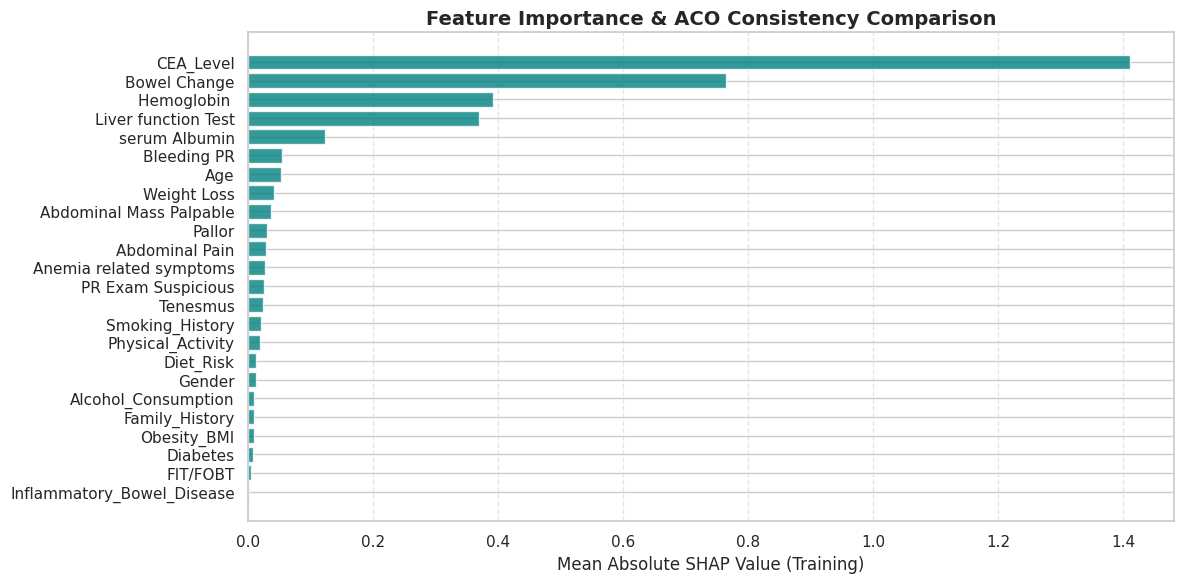

[SUCCESS] Comparative analysis and master table generated successfully!


In [54]:
# ==============================================================================
# COMPARATIVE ANALYSIS: ACO FEATURE SELECTION VS. SHAP FEATURE IMPORTANCE
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("=" * 80)
print("     ACO VS. SHAP COMPARATIVE ANALYSIS PIPELINE     ")
print("=" * 80)

# Step 1: Create a comprehensive comparison DataFrame for the Training Cohort
# Combine SHAP importance values with ACO selection flags
shap_train_full = pd.DataFrame({
    'Feature': features_d1,
    'Mean_Absolute_SHAP_Train': np.mean(np.abs(shap_values_train.values), axis=0)
}).sort_values(by='Mean_Absolute_SHAP_Train', ascending=False).reset_index(drop=True)

shap_train_full['SHAP_Rank_Train'] = shap_train_full.index + 1
shap_train_full['Selected_by_ACO_Train'] = shap_train_full['Feature'].isin(aco_selected_features)

print("\n[INFO] Training Cohort: ACO vs SHAP Feature Ranking:")
print(shap_train_full.to_string(index=False))

# Step 2: Create a comprehensive comparison DataFrame for the Pakistani Cohort
shap_pk_full = pd.DataFrame({
    'Feature': features_d1,
    'Mean_Absolute_SHAP_PK': np.mean(np.abs(shap_values_pk.values), axis=0)
}).sort_values(by='Mean_Absolute_SHAP_PK', ascending=False).reset_index(drop=True)

shap_pk_full['SHAP_Rank_PK'] = shap_pk_full.index + 1
shap_pk_full['Selected_by_ACO_PK'] = shap_pk_full['Feature'].isin(aco_selected_features_pk)

print("\n[INFO] Pakistani Cohort: ACO vs SHAP Feature Ranking:")
print(shap_pk_full.to_string(index=False))

# Step 3: Merge both cohorts into a master cross-validation table
master_comparison = pd.merge(
    shap_train_full,
    shap_pk_full[['Feature', 'SHAP_Rank_PK', 'Selected_by_ACO_PK']],
    on='Feature'
).sort_values(by='SHAP_Rank_Train').reset_index(drop=True)

print("\n" + "=" * 80)
print("     MASTER COMPARISON TABLE: TRAINING VS. PAKISTANI COHORT     ")
print("=" * 80)
print(master_comparison[['Feature', 'SHAP_Rank_Train', 'Selected_by_ACO_Train', 'SHAP_Rank_PK', 'Selected_by_ACO_PK']].to_string(index=False))
print("=" * 80)

# Step 4: Visualize the overlap between ACO selection and SHAP top rankings
plt.figure(figsize=(12, 6))
plt.barh(master_comparison['Feature'][::-1], master_comparison['Mean_Absolute_SHAP_Train'][::-1], color='teal', alpha=0.8)
plt.xlabel('Mean Absolute SHAP Value (Training)', fontsize=12)
plt.title('Feature Importance & ACO Consistency Comparison', fontsize=14, fontweight='bold')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()
print("[SUCCESS] Comparative analysis and master table generated successfully!")
print("=" * 80)

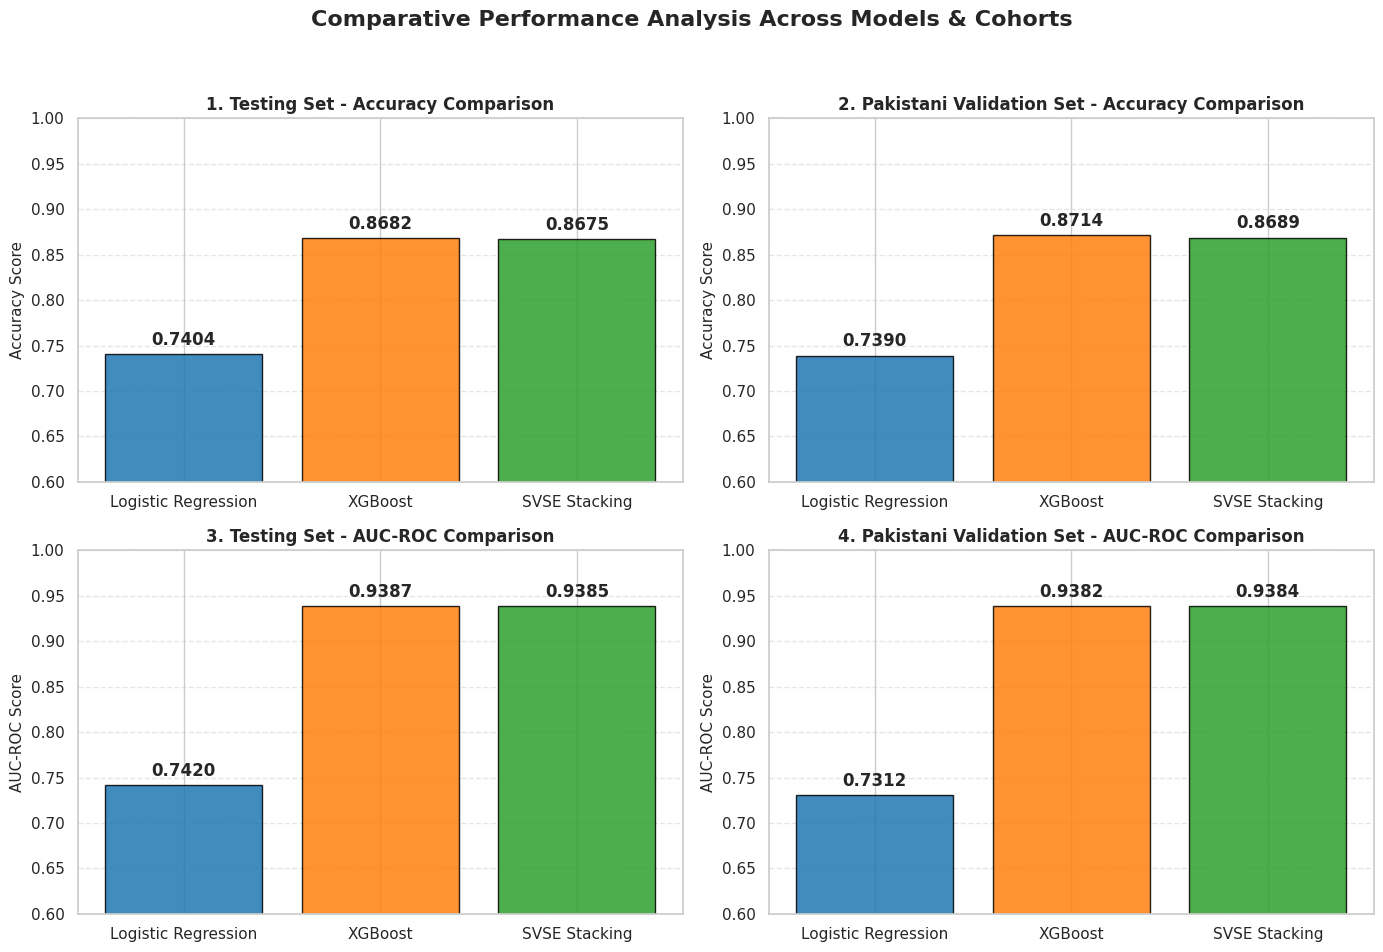

[SUCCESS] All 4 comparative evaluation charts generated successfully!


In [55]:
# ==============================================================================
# COMPARATIVE PERFORMANCE VISUALIZATION: TESTING VS. PAKISTANI VALIDATION
# ==============================================================================

import matplotlib.pyplot as plt
import numpy as np

# Define models and their collected metrics from your pipeline outputs
models = ['Logistic Regression', 'XGBoost', 'SVSE Stacking']

# 1. Testing Set Metrics (from your evaluation steps)
test_accuracy = [acc_lr, acc_xgb, acc_svse]        # Using threshold-tuned or default metrics
test_auc = [auc_lr, auc_xgb, auc_svse]

# 2. Pakistani Validation Set Metrics
val_accuracy = [acc_lr_pk, acc_xgb_pk, acc_svse_pk]
val_auc = [auc_lr_pk, auc_xgb_pk, auc_svse_pk]

# Set up the figure with 4 subplots (2x2 grid)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Comparative Performance Analysis Across Models & Cohorts', fontsize=16, fontweight='bold')

colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

# Chart 1: Testing Set Accuracy
axes[0, 0].bar(models, test_accuracy, color=colors, alpha=0.85, edgecolor='black')
axes[0, 0].set_title('1. Testing Set - Accuracy Comparison', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Accuracy Score', fontsize=11)
axes[0, 0].set_ylim(0.6, 1.0)
for i, v in enumerate(test_accuracy):
    axes[0, 0].text(i, v + 0.01, f"{v:.4f}", ha='center', fontweight='bold')
axes[0, 0].grid(axis='y', linestyle='--', alpha=0.5)

# Chart 2: Pakistani Validation Set Accuracy
axes[0, 1].bar(models, val_accuracy, color=colors, alpha=0.85, edgecolor='black')
axes[0, 1].set_title('2. Pakistani Validation Set - Accuracy Comparison', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('Accuracy Score', fontsize=11)
axes[0, 1].set_ylim(0.6, 1.0)
for i, v in enumerate(val_accuracy):
    axes[0, 1].text(i, v + 0.01, f"{v:.4f}", ha='center', fontweight='bold')
axes[0, 1].grid(axis='y', linestyle='--', alpha=0.5)

# Chart 3: Testing Set AUC-ROC
axes[1, 0].bar(models, test_auc, color=colors, alpha=0.85, edgecolor='black')
axes[1, 0].set_title('3. Testing Set - AUC-ROC Comparison', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('AUC-ROC Score', fontsize=11)
axes[1, 0].set_ylim(0.6, 1.0)
for i, v in enumerate(test_auc):
    axes[1, 0].text(i, v + 0.01, f"{v:.4f}", ha='center', fontweight='bold')
axes[1, 0].grid(axis='y', linestyle='--', alpha=0.5)

# Chart 4: Pakistani Validation Set AUC-ROC
axes[1, 1].bar(models, val_auc, color=colors, alpha=0.85, edgecolor='black')
axes[1, 1].set_title('4. Pakistani Validation Set - AUC-ROC Comparison', fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel('AUC-ROC Score', fontsize=11)
axes[1, 1].set_ylim(0.6, 1.0)
for i, v in enumerate(val_auc):
    axes[1, 1].text(i, v + 0.01, f"{v:.4f}", ha='center', fontweight='bold')
axes[1, 1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

print("[SUCCESS] All 4 comparative evaluation charts generated successfully!")

In [58]:
# ==============================================================================
# ULTIMATE MASTER EXCEL EXPORT: MODELS, ACO, & SHAP COMPREHENSIVE REPORT
# ==============================================================================

import pandas as pd
import numpy as np

print("=" * 80)
print("     GENERATING ULTIMATE MASTER EXCEL REPORT     ")
print("=" * 80)

# 1. Model Performance Summary Table
performance_data = {
    'Model': [
        'Logistic Regression', 'XGBoost', 'SVSE Stacking',
        'Logistic Regression', 'XGBoost', 'SVSE Stacking'
    ],
    'Cohort': [
        'Testing Set', 'Testing Set', 'Testing Set',
        'Pakistan Validation Set', 'Pakistan Validation Set', 'Pakistan Validation Set'
    ],
    'Accuracy': [
        acc_lr, acc_xgb, acc_svse,
        acc_lr_pk, acc_xgb_pk, acc_svse_pk
    ],
    'AUC_ROC': [
        auc_lr, auc_xgb, auc_svse,
        auc_lr_pk, auc_xgb_pk, auc_svse_pk
    ],
    'Precision': [
        prec_lr, prec_xgb, prec_svse,
        prec_lr_pk, prec_xgb_pk, prec_svse_pk
    ],
    'Recall_Sensitivity': [
        rec_lr, rec_xgb, rec_svse,
        rec_lr_pk, rec_xgb_pk, rec_svse_pk
    ],
    'F1_Score': [
        f1_lr, f1_xgb, f1_svse,
        f1_lr_pk, f1_xgb_pk, f1_svse_pk
    ]
}
df_performance_summary = pd.DataFrame(performance_data)

# 2. Detailed Training SHAP & ACO Integration Table
df_train_shap_aco = pd.DataFrame({
    'Feature': features_d1,
    'Mean_Absolute_SHAP_Train': np.mean(np.abs(shap_values_train.values), axis=0),
    'SHAP_Rank_Train': pd.Series(np.mean(np.abs(shap_values_train.values), axis=0)).rank(ascending=False).astype(int),
    'Selected_by_ACO_Train': [f in aco_selected_features for f in features_d1]
}).sort_values(by='SHAP_Rank_Train').reset_index(drop=True)

# 3. Detailed Pakistani Validation SHAP & ACO Integration Table
df_pk_shap_aco = pd.DataFrame({
    'Feature': features_d1,
    'Mean_Absolute_SHAP_PK': np.mean(np.abs(shap_values_pk.values), axis=0),
    'SHAP_Rank_PK': pd.Series(np.mean(np.abs(shap_values_pk.values), axis=0)).rank(ascending=False).astype(int),
    'Selected_by_ACO_PK': [f in aco_selected_features_pk for f in features_d1]
}).sort_values(by='SHAP_Rank_PK').reset_index(drop=True)

# 4. Master Cross-Cohort Comparison Table (JO AAPNE PEHLE DEKHI THI)
df_master_comparison = master_comparison.copy()

# Write everything into a multi-sheet Excel file using openpyxl
excel_filename = 'colorectal_cancer_ultimate_master_report.xlsx'

with pd.ExcelWriter(excel_filename, engine='openpyxl') as writer:
    df_performance_summary.to_excel(writer, sheet_name='Model_Performance_Summary', index=False)
    df_train_shap_aco.to_excel(writer, sheet_name='Training_SHAP_and_ACO', index=False)
    df_pk_shap_aco.to_excel(writer, sheet_name='Pakistani_SHAP_and_ACO', index=False)
    df_master_comparison.to_excel(writer, sheet_name='Master_Feature_Comparison', index=False)

print(f"[SUCCESS] Ultimate Master Report saved successfully as: '{excel_filename}'")
print("=" * 80)

# Automatically trigger download if running inside Google Colab
try:
    from google.log import * # Dummy import guard or just colab files
    from google.colab import files
    files.download(excel_filename)
    print("[INFO] File download triggered successfully in Google Colab.")
except ImportError:
    print("[INFO] Local environment detected; file saved in root directory.")

     GENERATING ULTIMATE MASTER EXCEL REPORT     
[SUCCESS] Ultimate Master Report saved successfully as: 'colorectal_cancer_ultimate_master_report.xlsx'
[INFO] Local environment detected; file saved in root directory.


     GENERATING INTUITIVE CONFUSION MATRICES GRID     


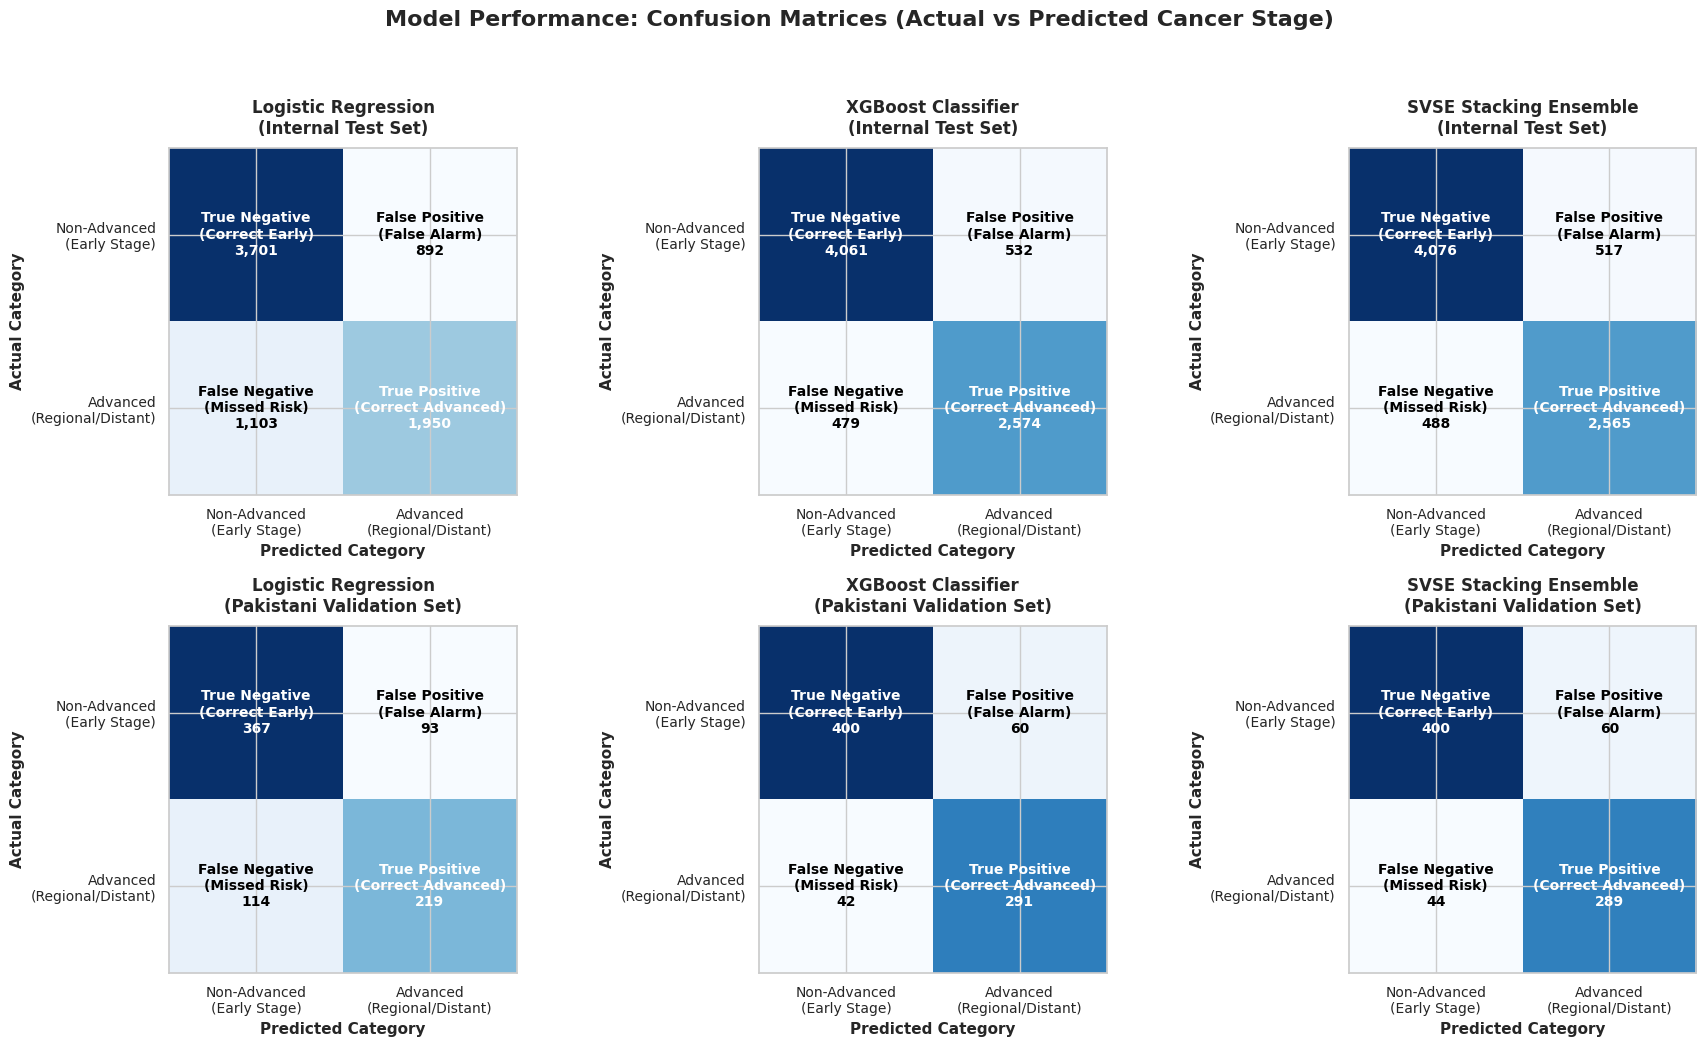

[SUCCESS] Intuitive confusion matrices generated and saved successfully!


In [60]:
# ==============================================================================
# INTUITIVE CONFUSION MATRICES GRID
# ==============================================================================

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix

print("=" * 80)
print("     GENERATING INTUITIVE CONFUSION MATRICES GRID     ")
print("=" * 80)

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle('Model Performance: Confusion Matrices (Actual vs Predicted Cancer Stage)', fontsize=16, fontweight='bold', y=0.98)

# Define models and their predictions
test_preds = [
    (y_pred_lr_opt, "Logistic Regression\n(Internal Test Set)"),
    (y_pred_xgb_opt, "XGBoost Classifier\n(Internal Test Set)"),
    (y_pred_svse_opt, "SVSE Stacking Ensemble\n(Internal Test Set)")
]

pk_preds = [
    (p_lr_pk_pred, "Logistic Regression\n(Pakistani Validation Set)"),
    (p_xgb_pk_pred, "XGBoost Classifier\n(Pakistani Validation Set)"),
    (p_svse_pk_pred, "SVSE Stacking Ensemble\n(Pakistani Validation Set)")
]

class_labels = ['Non-Advanced\n(Early Stage)', 'Advanced\n(Regional/Distant)']

def plot_custom_confusion_matrix(cm, ax, title):
    # Normalize or use raw counts with clean annotations
    ax.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    ax.set_title(title, fontsize=12, fontweight='bold', pad=10)

    tick_marks = np.arange(len(class_labels))
    ax.set_xticks(tick_marks)
    ax.set_xticklabels(class_labels, fontsize=10)
    ax.set_yticks(tick_marks)
    ax.set_yticklabels(class_labels, fontsize=10)

    ax.set_ylabel('Actual Category', fontsize=11, fontweight='bold')
    ax.set_xlabel('Predicted Category', fontsize=11, fontweight='bold')

    # Add text annotations with clear breakdown
    thresh = cm.max() / 2.0
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            val = cm[i, j]
            # Custom descriptive sub-text for each cell
            if i == 0 and j == 0:
                label_txt = f"True Negative\n(Correct Early)\n{val:,}"
            elif i == 0 and j == 1:
                label_txt = f"False Positive\n(False Alarm)\n{val:,}"
            elif i == 1 and j == 0:
                label_txt = f"False Negative\n(Missed Risk)\n{val:,}"
            else:
                label_txt = f"True Positive\n(Correct Advanced)\n{val:,}"

            ax.text(j, i, label_txt,
                    ha="center", va="center",
                    color="white" if val > thresh else "black",
                    fontsize=10, fontweight='bold')

# Plot Testing Set Confusion Matrices (Row 0)
for idx, (pred, title) in enumerate(test_preds):
    cm = confusion_matrix(y_test, pred)
    plot_custom_confusion_matrix(cm, axes[0, idx], title)

# Plot Pakistani Validation Set Confusion Matrices (Row 1)
for idx, (pred, title) in enumerate(pk_preds):
    cm = confusion_matrix(y_pakistan, pred)
    plot_custom_confusion_matrix(cm, axes[1, idx], title)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig('intuitive_confusion_matrices.png', dpi=300, bbox_inches='tight')
plt.show()

print("[SUCCESS] Intuitive confusion matrices generated and saved successfully!")
print("=" * 80)